In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

df = pd.read_excel(
    "Trend Data Combined.ods",
    engine="odf"
)

In [2]:
df["status"] = df["status"].astype(str).str.strip().str.lower()

print(df["status"].value_counts())

y = df["status"].map({
    "healthy": 0,
    "injured": 1
})

status
healthy    28
injured     5
Name: count, dtype: int64


In [3]:
health_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
    "hrv_deviation",
    "hr_drift"
]

running_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index",
    "chronic_load",
    "max_streak",
    "max_mileage_increase",
    "avg_mileage_change"
]

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [5]:
def run_decision_tree(X, y, category_name):

    model = DecisionTreeClassifier(
        max_depth=3,
        class_weight="balanced",
        random_state=42
    )

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{category_name} - Decision Tree")
    print("-" * 40)

    for metric in scoring:
        scores = results["test_" + metric]

        print(
            f"{metric}: "
            f"{scores.mean():.3f} +/- {scores.std():.3f}"
        )

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    cm = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Healthy", "Injured"]
    )

    disp.plot()
    plt.title(
        f"Decision Tree - {category_name}"
    )
    plt.show()

    print(
        classification_report(
            y,
            y_pred,
            labels=[0, 1],
            target_names=["Healthy", "Injured"],
            zero_division=0
        )
    )

    return model, results


Health Features - Decision Tree
----------------------------------------
accuracy: 0.610 +/- 0.187
balanced_accuracy: 0.440 +/- 0.210
precision: 0.067 +/- 0.133
recall: 0.200 +/- 0.400
f1: 0.100 +/- 0.200


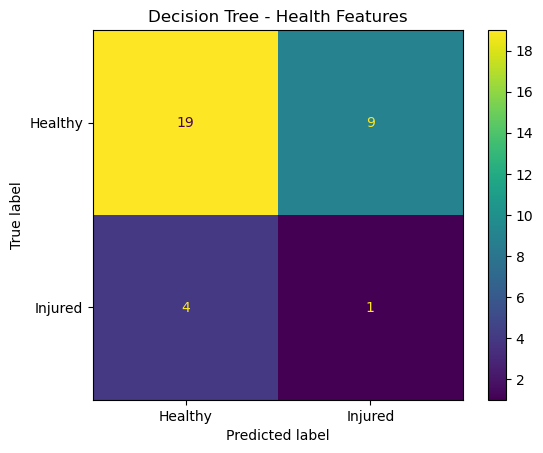

              precision    recall  f1-score   support

     Healthy       0.83      0.68      0.75        28
     Injured       0.10      0.20      0.13         5

    accuracy                           0.61        33
   macro avg       0.46      0.44      0.44        33
weighted avg       0.72      0.61      0.65        33



In [6]:
X_health = df[health_features]

tree_health, tree_health_results = run_decision_tree(
    X_health,
    y,
    "Health Features"
)


Running Features - Decision Tree
----------------------------------------
accuracy: 0.733 +/- 0.097
balanced_accuracy: 0.597 +/- 0.228
precision: 0.167 +/- 0.211
recall: 0.400 +/- 0.490
f1: 0.233 +/- 0.291


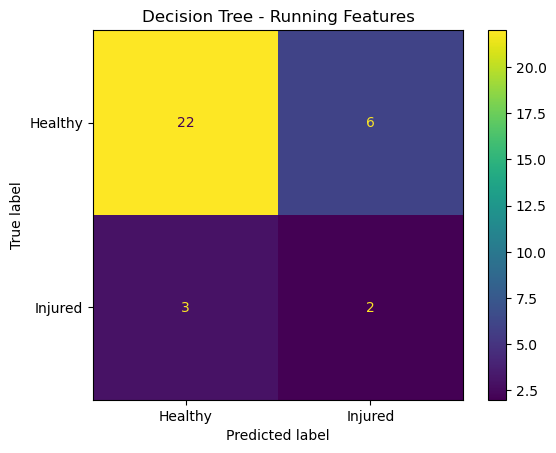

              precision    recall  f1-score   support

     Healthy       0.88      0.79      0.83        28
     Injured       0.25      0.40      0.31         5

    accuracy                           0.73        33
   macro avg       0.56      0.59      0.57        33
weighted avg       0.78      0.73      0.75        33



In [7]:
X_running = df[running_features]

tree_running, tree_running_results = run_decision_tree(
    X_running,
    y,
    "Running Features"
)

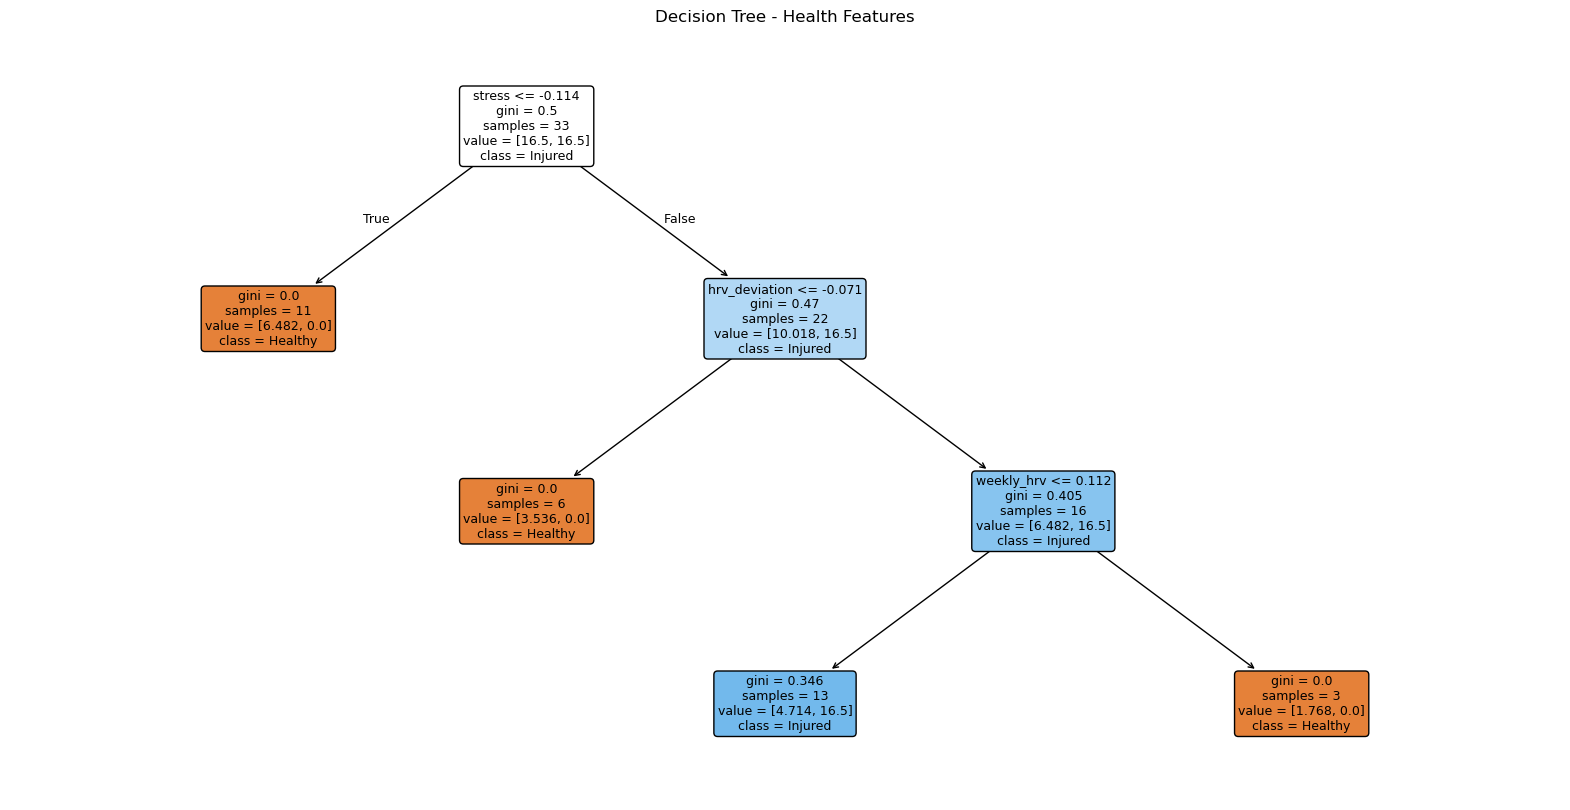

In [8]:
tree_health.fit(X_health, y)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_health,
    feature_names=health_features,
    class_names=["Healthy", "Injured"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Health Features")
plt.show()

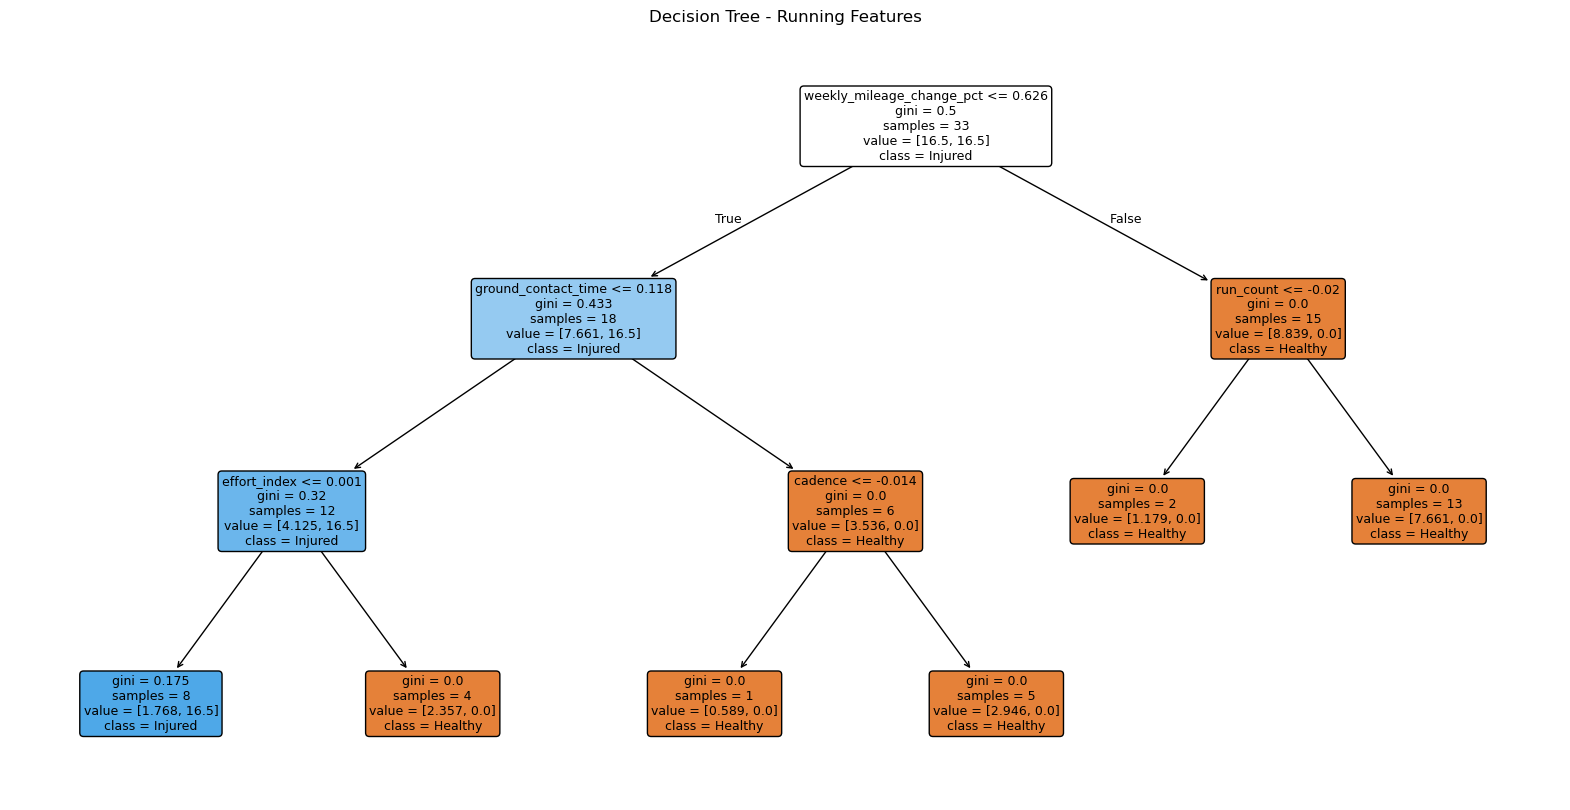

In [9]:
tree_running.fit(X_running, y)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_running,
    feature_names=running_features,
    class_names=["Healthy", "Injured"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Running Features")
plt.show()

In [10]:
def show_tree_importance(model, features, title):

    importance = pd.DataFrame({
        "Feature": features,
        "Importance": model.feature_importances_
    })

    importance = importance.sort_values(
        "Importance",
        ascending=False
    )

    print(importance)

    importance = importance[
        importance["Importance"] > 0
    ]

    plt.figure(figsize=(10, 6))

    plt.barh(
        importance["Feature"],
        importance["Importance"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Feature Importance")
    plt.title(title)

    plt.show()

               Feature  Importance
1               stress    0.440000
10       hrv_deviation    0.344615
3           weekly_hrv    0.215385
0   resting_heart_rate    0.000000
2          nightly_hrv    0.000000
4       sleep_duration    0.000000
6           deep_sleep    0.000000
5          sleep_score    0.000000
7          light_sleep    0.000000
8            rem_sleep    0.000000
9       awake_duration    0.000000
11            hr_drift    0.000000


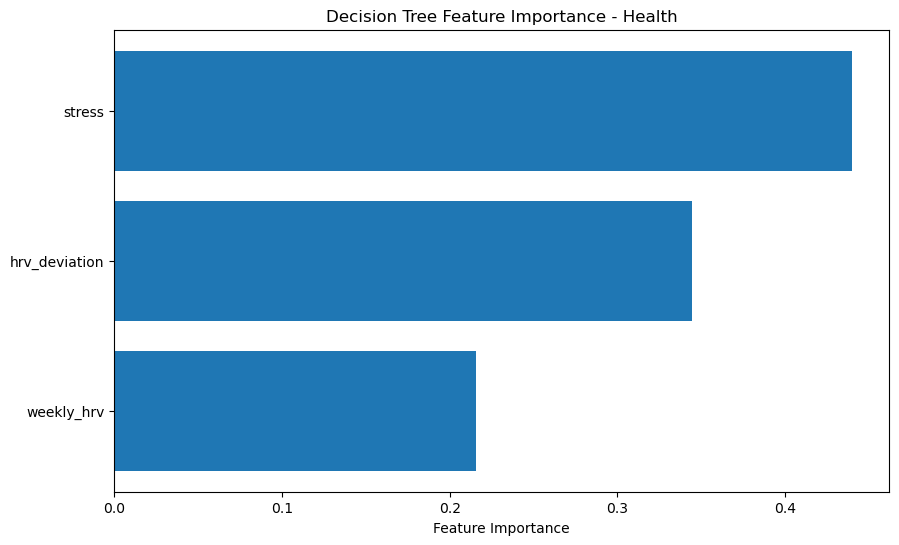

                      Feature    Importance
3   weekly_mileage_change_pct  4.536585e-01
4         ground_contact_time  2.903415e-01
9                effort_index  2.560000e-01
0                   run_count  3.761277e-15
5                     cadence  7.965057e-16
1                    distance  0.000000e+00
2                elapsed_time  0.000000e+00
6          running_heart_rate  0.000000e+00
7                elapsed_pace  0.000000e+00
8               stride_length  0.000000e+00
10               chronic_load  0.000000e+00
11                 max_streak  0.000000e+00
12       max_mileage_increase  0.000000e+00
13         avg_mileage_change  0.000000e+00


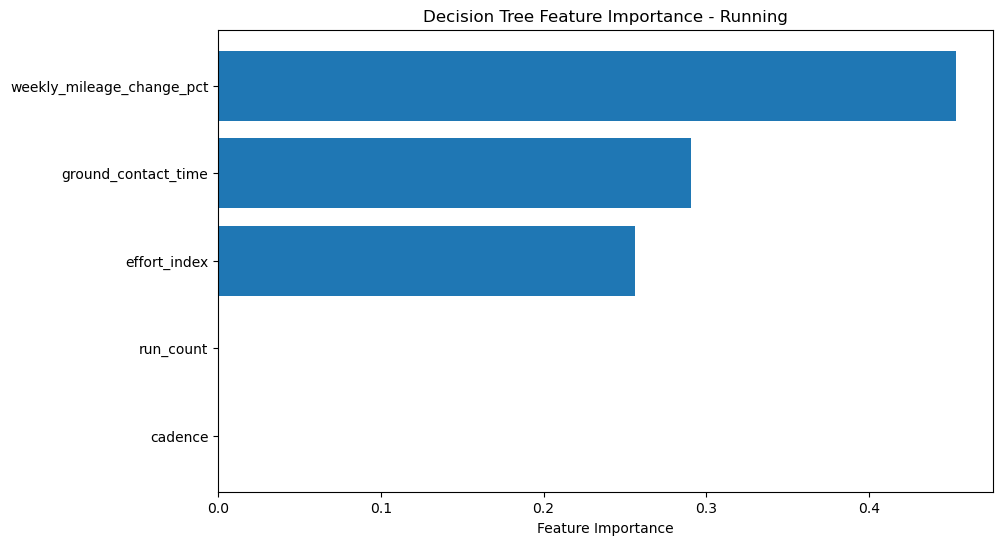

In [11]:
show_tree_importance(
    tree_health,
    health_features,
    "Decision Tree Feature Importance - Health"
)

show_tree_importance(
    tree_running,
    running_features,
    "Decision Tree Feature Importance - Running"
)